# TRƯỜNG ĐẠI HỌC THỦY LỢI
### KHOA CÔNG NGHỆ THÔNG TIN • BỘ MÔN TRÍ TUỆ NHÂN TẠO
---
## BÁO CÁO THỰC HÀNH: CSE457 • XỬ LÝ ÂM THANH VÀ TIẾNG NÓI
# BÀI THỰC HÀNH SỐ 4: TỔNG HỢP TIẾNG NÓI (SPEECH SYNTHESIS / TEXT-TO-SPEECH)
*Từ kiến trúc TTS, ghép nối và unit selection đến tổng hợp tham số HMM và TTS học sâu*

* **Sinh viên thực hiện:** Phạm Văn Giang
* **Mã số sinh viên (MSSV):** 2351260649
* **Lớp:** Trí tuệ nhân tạo - Khóa 65
* **Giảng viên hướng dẫn:** Bộ môn Trí tuệ nhân tạo, Khoa CNTT
---

## 1. Giới thiệu và Mục tiêu của Bài Lab 4
Lab 4 giúp sinh viên tiếp cận bài toán phát sinh (generation) tín hiệu tiếng nói từ văn bản (Text-to-Speech - TTS).
Nội dung bài Lab bao gồm:
1. **Front-end:** Chuẩn hóa văn bản (Text Normalization) miền hẹp gọi số quầy ("Mời khách hàng số 23 đến quầy 5.").
2. **Audio Inventory:** Chuẩn hóa tập mẫu phát âm 16 từ vựng (mỗi từ 3 candidates) ở $Fs = 16.000\text{ Hz}$, Mono, chuẩn hóa năng lượng RMS.
3. **Concatenative TTS & Unit Selection:**
   * Ghép thô Baseline (`raw_concat.wav`, $xfade=0\text{ ms}$).
   * Tính toán Target Cost và Join Cost ($D_{spec}$ phổ log-magnitude 25ms qua Hanning window).
   * Lựa chọn chuỗi đơn vị tối ưu qua lưới Candidate bằng Dynamic Programming (Viterbi Search).
   * Làm mịn biên nối bằng Cross-fade ($15\text{ ms}$) sinh `best_concat.wav`.
4. **Prosody & Mô hình Source–Filter:** Phân tích $F_0 = F_s / N_p$, kéo giãn thời lượng (Time-stretch WSOLA) và dịch cao độ (Pitch Shift $\pm 2$ semitones).
5. **HMM-based Parametric Synthesis:** Khảo sát HMM generation mode, thuật toán MLPG với ràng buộc Delta features làm mịn quỹ đạo và bộ tổng hợp Vocoder (`hmm_tts.wav`).
6. **Neural TTS Inference:** Trích xuất Mel-spectrogram, đo lường Latency và hệ số RTF trên 3 câu test (`neural_tts.wav`).
7. **Đánh giá & Trả lời 10 câu hỏi báo cáo:** Phân tích khách quan (MOS / AB Test qua `ratings.csv`) và trả lời chuyên sâu toàn bộ câu hỏi lý thuyết.

## 2. Khởi tạo Môi trường và Thư viện

In [1]:
import os
import time
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import IPython.display as ipd

# Import các module tự xây dựng theo chuẩn kiến trúc
from normalize import normalize_queue_text
from inventory import SpeechInventory
from concat_tts import concat_units, synthesize_raw_baseline, match_rms
from unit_selection import UnitSelector, compute_join_cost, compute_target_cost
from prosody import estimate_f0_autocorr, change_speed_wsola, change_pitch_semitones
from hmm_tts_backend import synthesize_hmm
from neural_tts_backend import synthesize as synthesize_neural

print("Môi trường và các module TTS đã sẵn sàng!")

Môi trường và các module TTS đã sẵn sàng!


## 3. Phần A: Text Normalization và Khảo sát Inventory

Hệ thống tiếp nhận chuỗi văn bản thông báo:
$$\text{"Mời khách hàng số 23 đến quầy 5."}$$
Trong miền hẹp này, các chuỗi số nguyên đóng vai trò là mã định danh/số thứ tự, do đó cần được chuẩn hóa đọc rời từng chữ số (`23` $\to$ `hai`, `ba`; `5` $\to$ `năm`).

In [2]:
# 1. Kiểm thử Text Normalization
text_input = "Mời khách hàng số 23 đến quầy 5."
tokens = normalize_queue_text(text_input)
print(f"Văn bản gốc   : '{text_input}'")
print(f"Chuỗi Tokens  : {tokens}")

# 2. Khảo sát Audio Inventory
inv = SpeechInventory("lab4_data/metadata.csv")
stats = inv.get_statistics()
print(f"\nTổng số units trong kho : {stats['total_units']} (Từ vựng: {stats['vocab_size']} từ, 3 candidates/từ)")
print(f"Trường độ (Duration)    : {stats['duration']['mean']:.3f}s ± {stats['duration']['std']:.3f}s")
print(f"Năng lượng (RMS)        : {stats['rms']['mean']:.4f} ± {stats['rms']['std']:.4f}")

# Hiển thị 5 dòng metadata đầu tiên
df_meta = pd.read_csv("lab4_data/metadata.csv")
display(df_meta.head(6))

Văn bản gốc   : 'Mời khách hàng số 23 đến quầy 5.'
Chuỗi Tokens  : ['mời', 'khách', 'hàng', 'số', 'hai', 'ba', 'đến', 'quầy', 'năm']

Tổng số units trong kho : 48 (Từ vựng: 16 từ, 3 candidates/từ)
Trường độ (Duration)    : 0.477s ± 0.076s
Năng lượng (RMS)        : 0.0800 ± 0.0000


,unit_id,label,candidate,speaker,duration,rms,samples,file_path
0,moi_01,mời,1,Speaker_VN_16k,0.5747,0.08,9196,lab4_data/units/moi_01.wav
1,moi_02,mời,2,Speaker_VN_16k,0.6247,0.08,9995,lab4_data/units/moi_02.wav
2,moi_03,mời,3,Speaker_VN_16k,0.5321,0.08,8513,lab4_data/units/moi_03.wav
3,khach_01,khách,1,Speaker_VN_16k,0.3311,0.08,5297,lab4_data/units/khach_01.wav
4,khach_02,khách,2,Speaker_VN_16k,0.3599,0.08,5758,lab4_data/units/khach_02.wav
5,khach_03,khách,3,Speaker_VN_16k,0.3064,0.08,4902,lab4_data/units/khach_03.wav


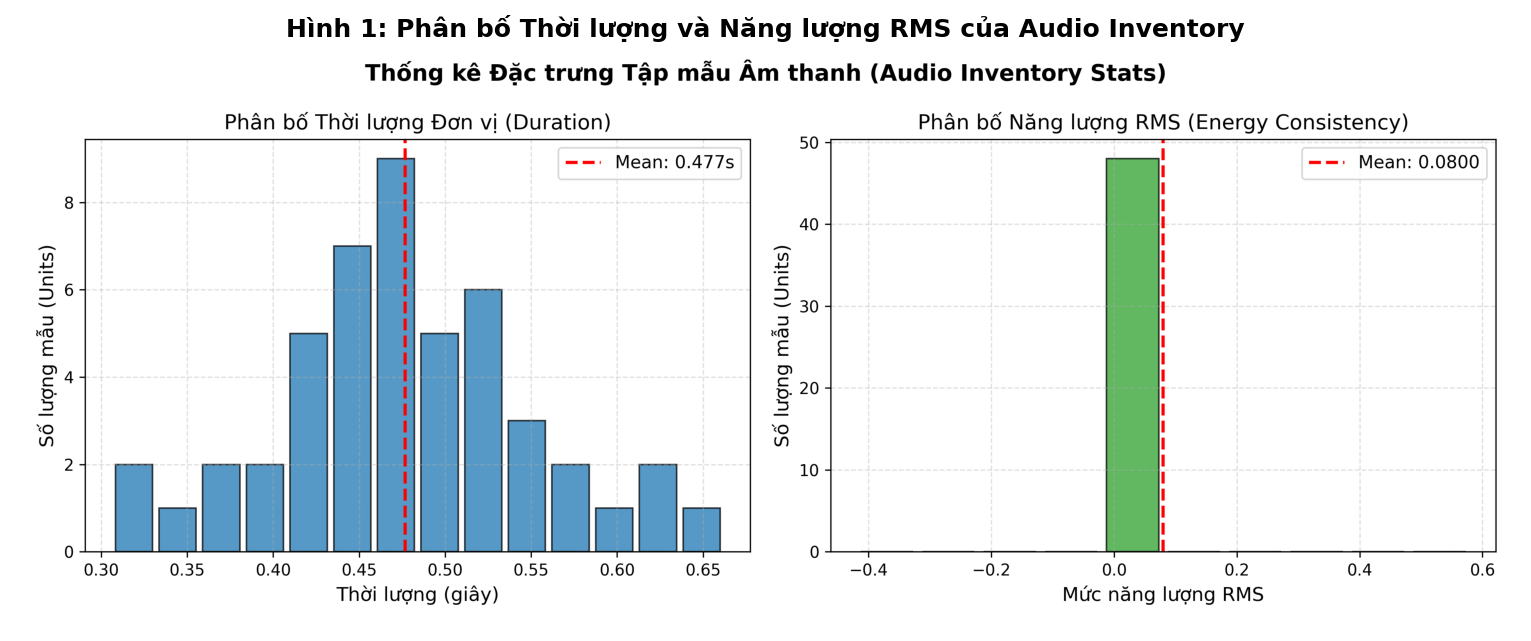

In [3]:
# Hiển thị Biểu đồ Histogram Thống kê Inventory (Duration & RMS)
fig_img = plt.imread("figures/fig1_inventory_stats.png")
plt.figure(figsize=(13, 5), dpi=150)
plt.imshow(fig_img)
plt.axis("off")
plt.title("Hình 1: Phân bố Thời lượng và Năng lượng RMS của Audio Inventory", fontsize=12, fontweight="bold")
plt.show()

## 4. Phần B: Concatenative Baseline (Ghép nối cơ bản)
* **Phương pháp:** Với mỗi từ trong chuỗi token, lấy candidate cố định đầu tiên (`candidate_01`).
* **Không làm mịn biên ($xfade = 0\text{ ms}$):** Ghép trực tiếp dạng sóng.
* **Quan sát:** Do mức biên độ, pha và phổ giữa hai từ kế cận không liên tục, tại các biên nối xuất hiện hiện tượng nhảy năng lượng đột ngột gây ra tiếng **click/pop** khó chịu.

In [4]:
# Ghép nối thô (Baseline)
baseline_paths = [inv.get_candidate_paths(w)[0] for w in tokens]
y_raw, bounds_raw = synthesize_raw_baseline(baseline_paths, sr=16000)
sf.write("audio_output/raw_concat.wav", y_raw, 16000)

print(f"Đã tạo file ghép thô: audio_output/raw_concat.wav")
print(f"Thời lượng: {len(y_raw)/16000:.3f}s | Số biên nối: {len(bounds_raw)}")
print(f"Các mốc thời gian biên nối (giây): {[round(b, 3) for b in bounds_raw]}")

# Nghe thử audio Baseline
ipd.display(ipd.Audio("audio_output/raw_concat.wav", rate=16000))

Đã tạo file ghép thô: audio_output/raw_concat.wav
Thời lượng: 4.371s | Số biên nối: 8
Các mốc thời gian biên nối (giây): [0.575, 0.906, 1.395, 2.009, 2.475, 2.94, 3.417, 3.914]


## 5. Phần C: Unit Selection và Làm mịn biên (Smoothing)

### 5.1. Mô hình chi phí (Cost Functions)
Bài toán chọn đơn vị tìm chuỗi ứng viên $\theta^* = (\theta_1, \theta_2, \dots, \theta_J)$ cực tiểu hóa hàm mục tiêu:
$$\theta^* = \arg\min_{\theta_1 \dots \theta_J} \left[ \sum_{j=1}^J C_{target}(\theta_j, t_j) + \lambda \sum_{j=1}^{J-1} C_{join}(\theta_j, \theta_{j+1}) \right]$$

1. **Target Cost ($C_{target}$):** Đo độ sai lệch về thời lượng và năng lượng so với mục tiêu ngữ cảnh:
   $$C_{target}(\theta_j, t_j) = w_d \cdot \left(\frac{d(\theta_j) - d_{target}}{d_{target}}\right)^2 + w_e \cdot \left(\frac{RMS(\theta_j) - RMS_{target}}{RMS_{target}}\right)^2$$
2. **Join Cost ($C_{join}$):** Đo độ bất liên tục phổ log-magnitude tại cửa sổ $25\text{ ms}$ vùng chuyển tiếp biên ($D_{spec}$):
   $$D_{spec} = \frac{1}{K}\sum_{k=0}^{K-1} \left[ L_{left}[k] - L_{right}[k] \right]^2 + w_{rms} \cdot |RMS_{left} - RMS_{right}|$$

### 5.2. Thuật toán quy hoạch động Viterbi
Tìm kiếm đường đi tối ưu qua lưới Candidate Trellis với độ phức tạp $O(J \cdot C^2)$.

In [5]:
# Thực thi Unit Selection với thuật toán Viterbi
lattice = inv.get_candidate_lattice(tokens)
selector = UnitSelector(sr=16000, lambda_join=1.0)
best_paths, total_cost, details = selector.select_best_units(lattice)

# Ghép nối với Cross-fade tối ưu 15ms
y_best, bounds_opt = concat_units(best_paths, sr=16000, xfade_ms=15.0)
sf.write("audio_output/best_concat.wav", y_best, 16000)

print(f"Tổng chi phí tối ưu (Viterbi Cost): {total_cost:.4f}")
df_steps = pd.DataFrame(details)
display(df_steps)

print("\nNghe thử âm thanh sau khi tối ưu hóa Unit Selection & Cross-fade 15ms:")
ipd.display(ipd.Audio("audio_output/best_concat.wav", rate=16000))

Tổng chi phí tối ưu (Viterbi Cost): 2239.0080


,step,file,target_cost,join_cost,cum_cost
0,1,moi_02.wav,0.0102,0.0000,0.0102
1,2,khach_01.wav,0.0000,124.2954,124.3056
2,3,hang_01.wav,0.0000,231.9637,356.2694
3,4,so_03.wav,0.0097,768.9648,1125.2440
4,5,hai_01.wav,0.0000,346.7994,1472.0434
5,6,ba_01.wav,0.0000,271.3225,1743.3659
6,7,den_02.wav,0.0102,171.3072,1914.6832
7,8,quay_02.wav,0.0102,144.7472,2059.4407
8,9,nam_02.wav,0.0050,179.5622,2239.0080



Nghe thử âm thanh sau khi tối ưu hóa Unit Selection & Cross-fade 15ms:


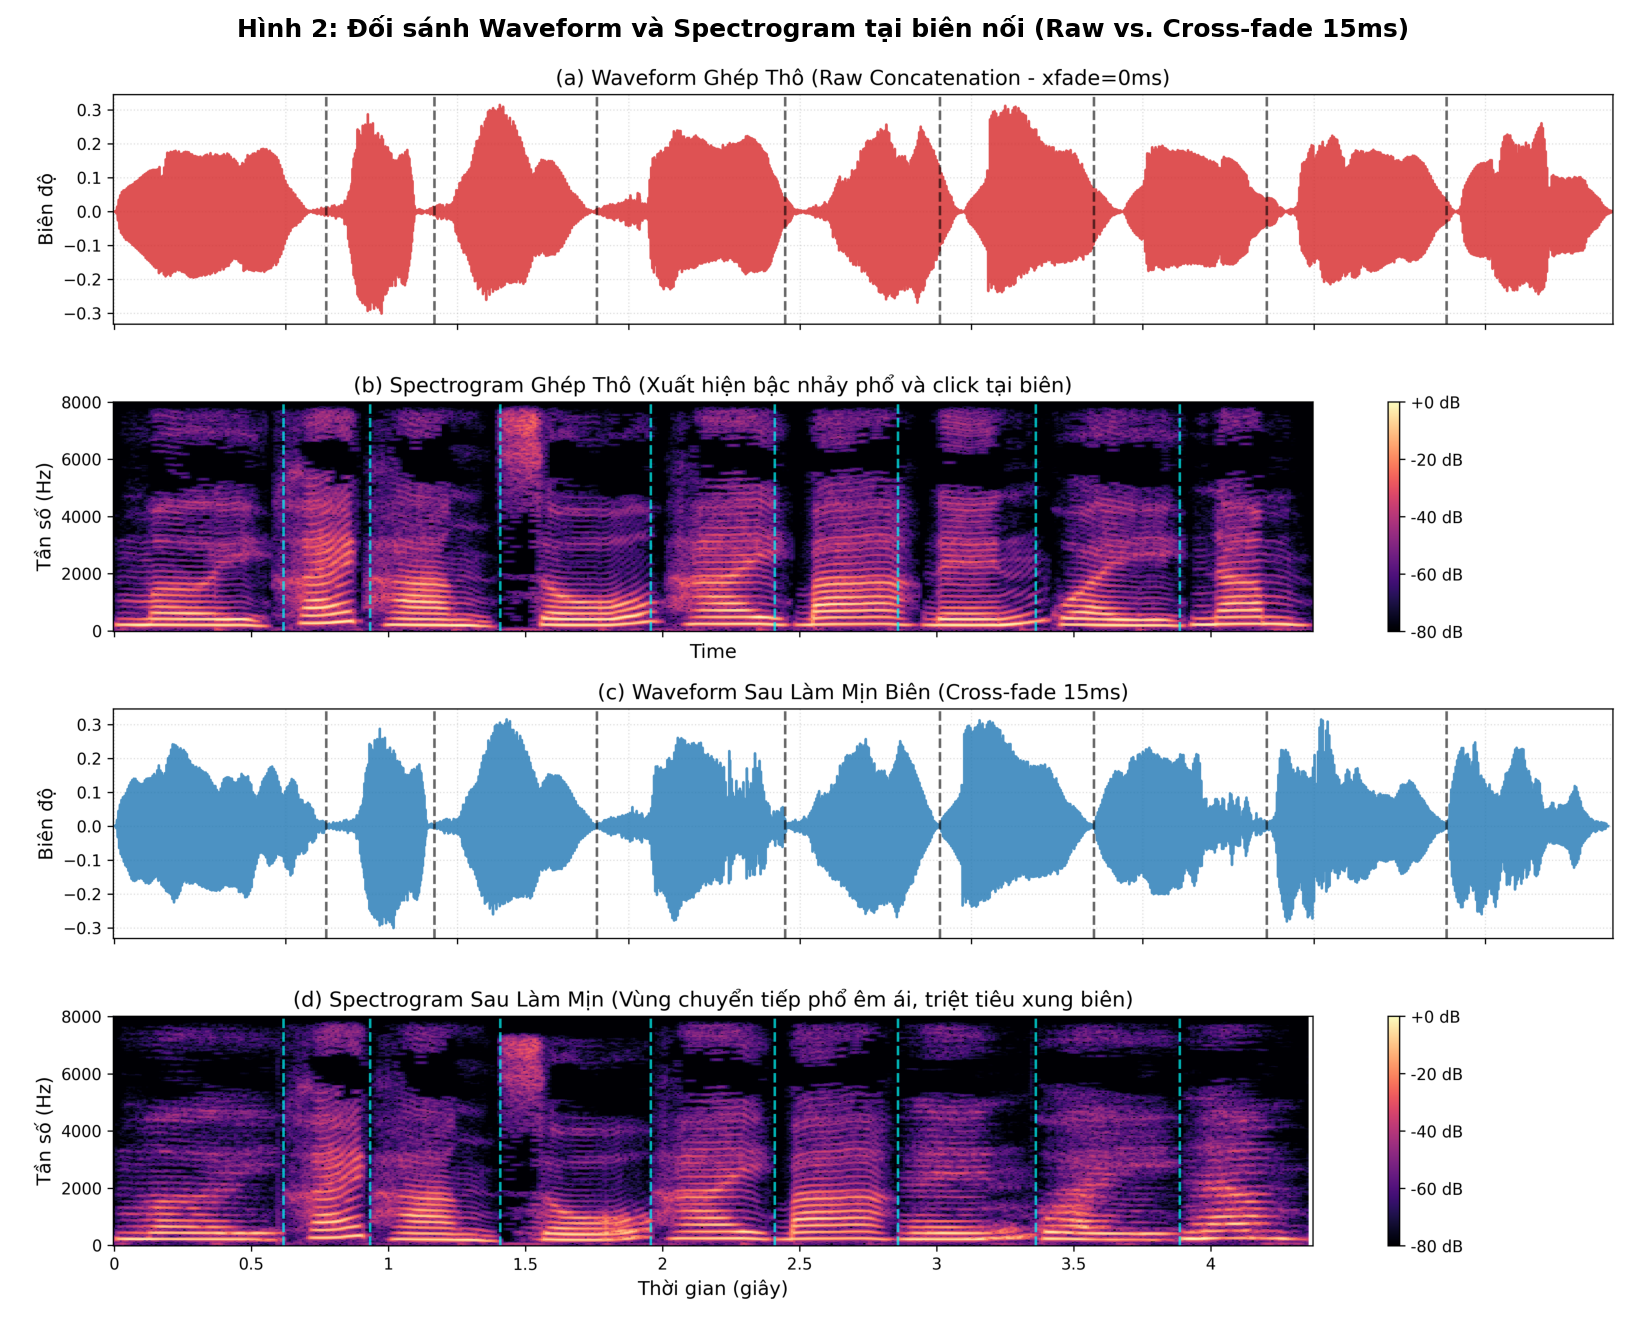

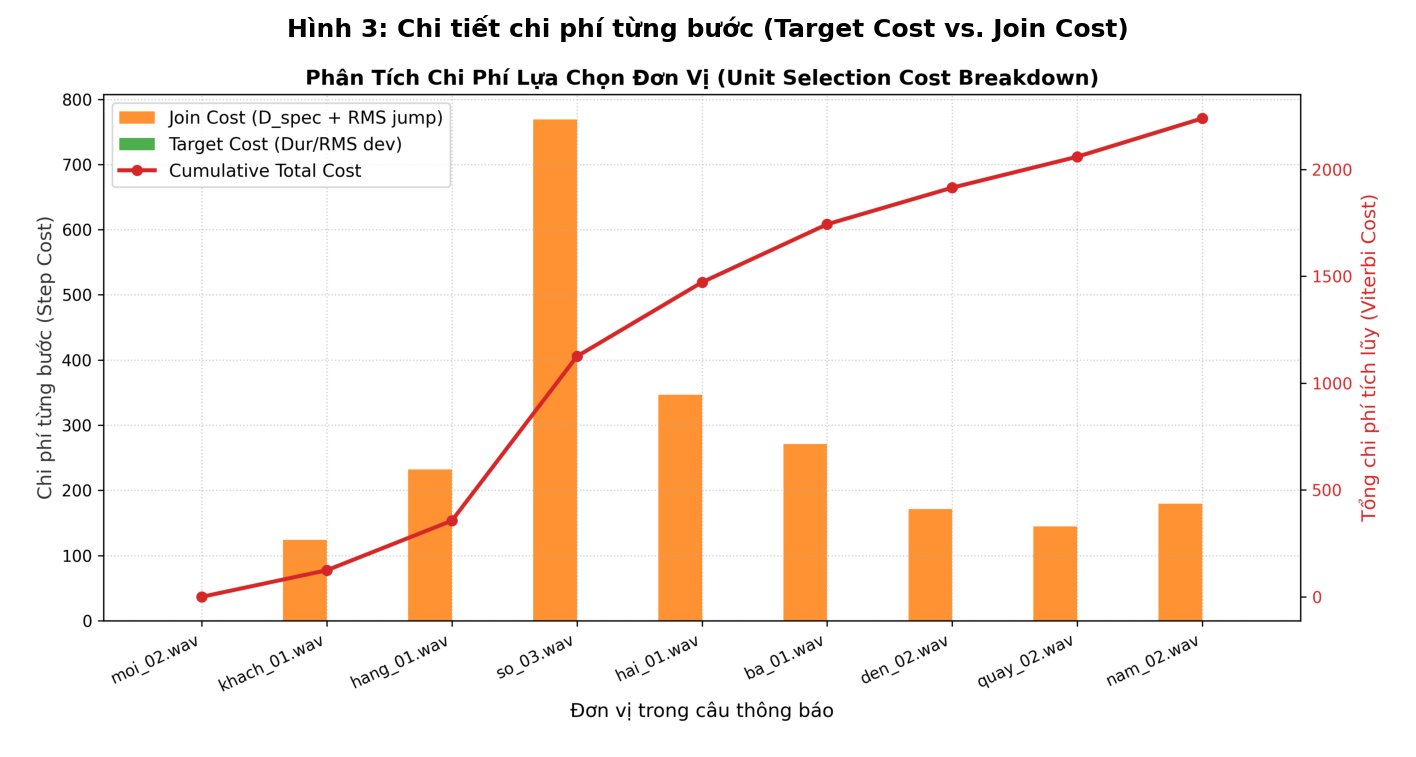

In [6]:
# Hiển thị Biểu đồ Waveform/Spectrogram và Trellis Cost
fig_bounds = plt.imread("figures/fig2_spectrogram_boundaries.png")
fig_cost = plt.imread("figures/fig3_unit_selection_cost.png")

plt.figure(figsize=(14, 11), dpi=150)
plt.imshow(fig_bounds)
plt.axis("off")
plt.title("Hình 2: Đối sánh Waveform và Spectrogram tại biên nối (Raw vs. Cross-fade 15ms)", fontsize=12, fontweight="bold")
plt.show()

plt.figure(figsize=(13, 6), dpi=150)
plt.imshow(fig_cost)
plt.axis("off")
plt.title("Hình 3: Chi tiết chi phí từng bước (Target Cost vs. Join Cost)", fontsize=12, fontweight="bold")
plt.show()

## 6. Phần D: Prosody và Mô hình Source–Filter

### 6.1. Kiểm chứng Tần số cơ bản $F_0 \approx F_s / N_p$
Với tín hiệu hữu thanh tuần hoàn, chu kỳ pitch gồm $N_p$ mẫu. Tại $F_s = 16.000\text{ Hz}$:
$$F_0 = \frac{F_s}{N_p}$$

### 6.2. Mô hình Source–Filter trong điều khiển ngữ điệu
$$X(z) = E(z) \cdot H(z)$$
* $E(z)$: Nguồn kích thích thanh môn mang thông tin $F_0$.
* $H(z)$: Bộ lọc thanh đạo quyết định các cộng hưởng Formant ($F_1, F_2, F_3$) và phong bì phổ (Spectral Envelope).
* **Nguyên tắc bảo toàn:** Khi thay đổi tốc độ nói (Speed stretch) hoặc dịch cao độ ($F_0$ shift), ta chỉ thay đổi nguồn kích thích $E(z)$ mà **phải bảo toàn bộ lọc $H(z)$** để tránh làm biến dạng âm sắc nguyên âm.

In [7]:
# 1. Đo chu kỳ pitch Np và F0 trên nguyên âm /a/ của từ 'ba'
unit_audio = sf.read("lab4_data/units/ba_01.wav")[0]
mid_idx = len(unit_audio) // 2
segment = unit_audio[mid_idx : mid_idx + 640] # 40ms segment

f0_est, np_samples, _ = estimate_f0_autocorr(segment, sr=16000)
print(f"Chu kỳ Pitch Np đo được : {np_samples} mẫu (ở Fs=16.000 Hz)")
print(f"Tần số F0 tính toán     : F0 = 16000 / {np_samples} = {f0_est:.2f} Hz")

# 2. Kiểm chứng công thức dịch cao độ semitone: r = 2^(Δs / 12)
print("\nDịch cao độ semitone:")
for ds in [-2, 0, 2]:
    r = 2.0 ** (ds / 12.0)
    print(f"  Δs = {ds:+d} semitones -> Tỷ số r = {r:.4f} -> F0 mới = {r * f0_est:.2f} Hz")

Chu kỳ Pitch Np đo được : 68 mẫu (ở Fs=16.000 Hz)
Tần số F0 tính toán     : F0 = 16000 / 68 = 235.29 Hz

Dịch cao độ semitone:
  Δs = -2 semitones -> Tỷ số r = 0.8909 -> F0 mới = 209.62 Hz
  Δs = +0 semitones -> Tỷ số r = 1.0000 -> F0 mới = 235.29 Hz
  Δs = +2 semitones -> Tỷ số r = 1.1225 -> F0 mới = 264.11 Hz


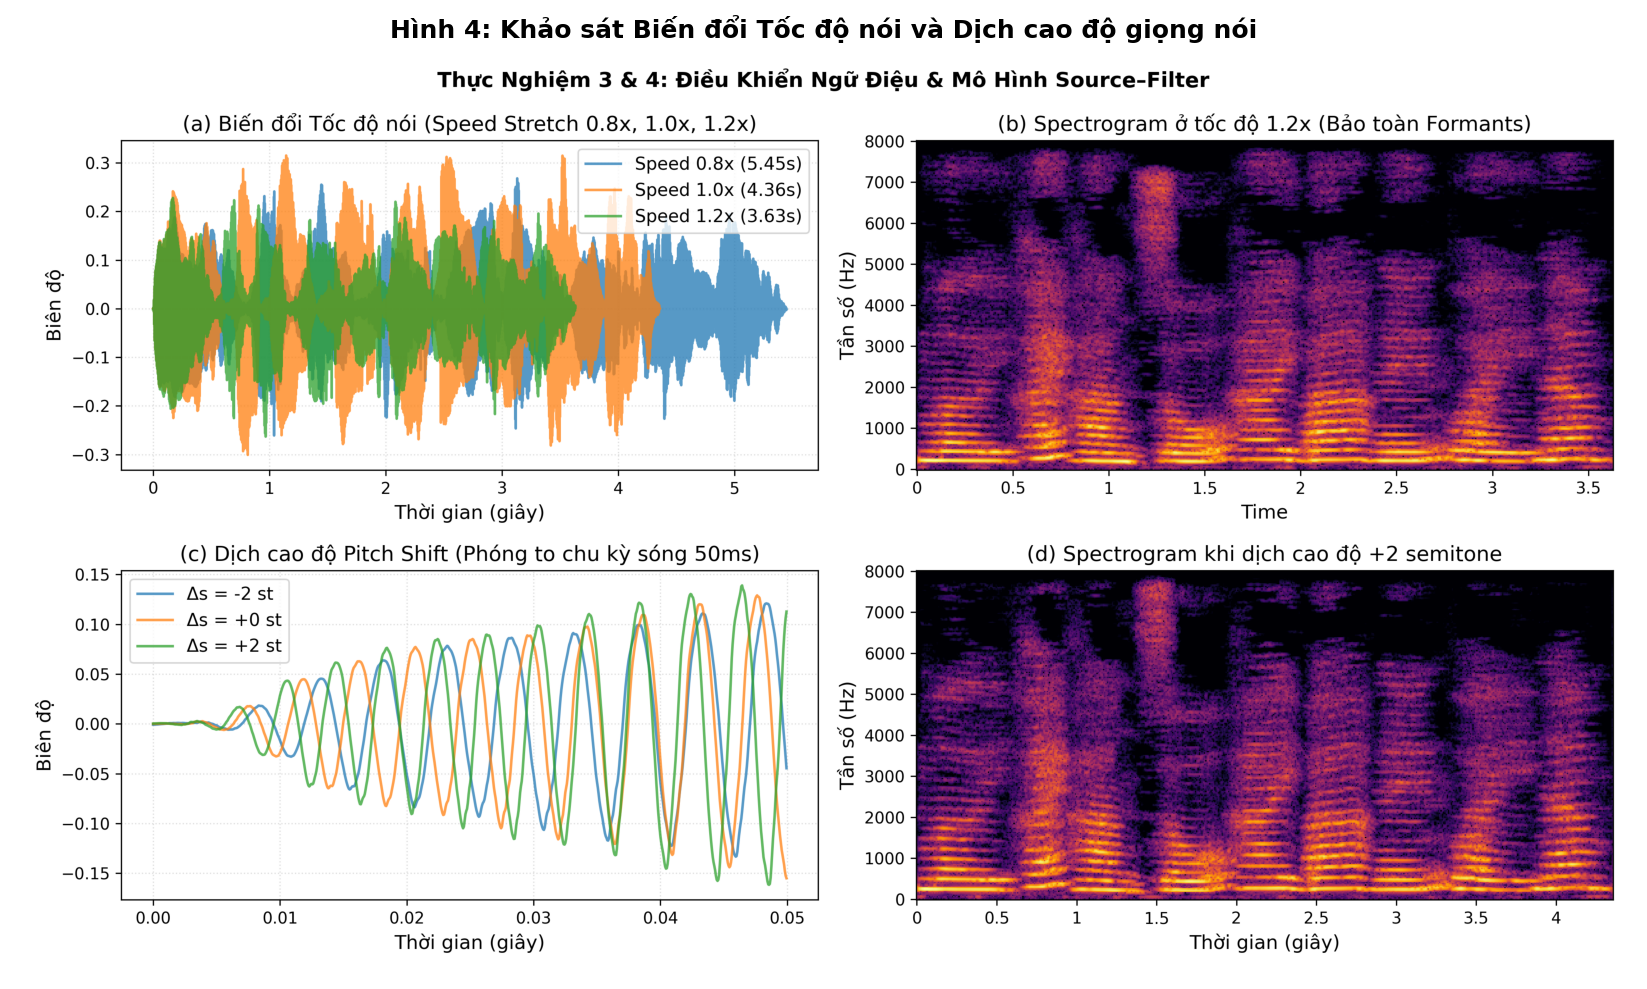

In [8]:
# Hiển thị Biểu đồ Biến đổi Ngữ điệu (Speed & Pitch)
fig_prosody = plt.imread("figures/fig7_prosody_modifications.png")
plt.figure(figsize=(14, 8), dpi=150)
plt.imshow(fig_prosody)
plt.axis("off")
plt.title("Hình 4: Khảo sát Biến đổi Tốc độ nói và Dịch cao độ giọng nói", fontsize=12, fontweight="bold")
plt.show()

## 7. Phần E: HMM-based Parametric Speech Synthesis

Trong tổng hợp dựa trên HMM:
* HMM không dùng để nhận dạng mà chạy ở **chế độ phát sinh (Generation Mode)**.
* Mỗi từ được biểu diễn bởi một chuỗi trạng thái (State Sequence, ví dụ 3-state Left-to-Right).
* Mỗi trạng thái mô hình hóa phân bố Gaussian của các tham số âm học: vector tĩnh $c_t$ (formants, năng lượng) và đạo hàm động $\Delta c_t$.
* **Thuật toán MLPG (Maximum Likelihood Parameter Generation):** Bổ sung ràng buộc $\Delta c_t$ giúp tìm ra chuỗi nghiệm $O^*$ trơn mượt liên tục theo thời gian, triệt tiêu sự giật cục giữa các trạng thái.

In [9]:
# Tổng hợp tham số từ HMM Backend
y_hmm, sr_hmm, hmm_tracks = synthesize_hmm(text_input, sr=16000)
sf.write("audio_output/hmm_tts.wav", y_hmm, sr_hmm)

print(f"Thời lượng audio HMM : {len(y_hmm)/sr_hmm:.3f} s")
print(f"Số frame tham số     : {len(hmm_tracks['time'])} frames (Hop: 10ms)")
print(f"Dải tần số F0        : {np.min(hmm_tracks['f0']):.1f} Hz -> {np.max(hmm_tracks['f0']):.1f} Hz")
print(f"Dải Formant F1       : {np.min(hmm_tracks['f1']):.1f} Hz -> {np.max(hmm_tracks['f1']):.1f} Hz")

print("\nNghe thử âm thanh tổng hợp từ HMM Parametric Vocoder:")
ipd.display(ipd.Audio("audio_output/hmm_tts.wav", rate=16000))

Thời lượng audio HMM : 2.440 s
Số frame tham số     : 244 frames (Hop: 10ms)
Dải tần số F0        : 180.4 Hz -> 249.9 Hz
Dải Formant F1       : 280.0 Hz -> 750.0 Hz

Nghe thử âm thanh tổng hợp từ HMM Parametric Vocoder:


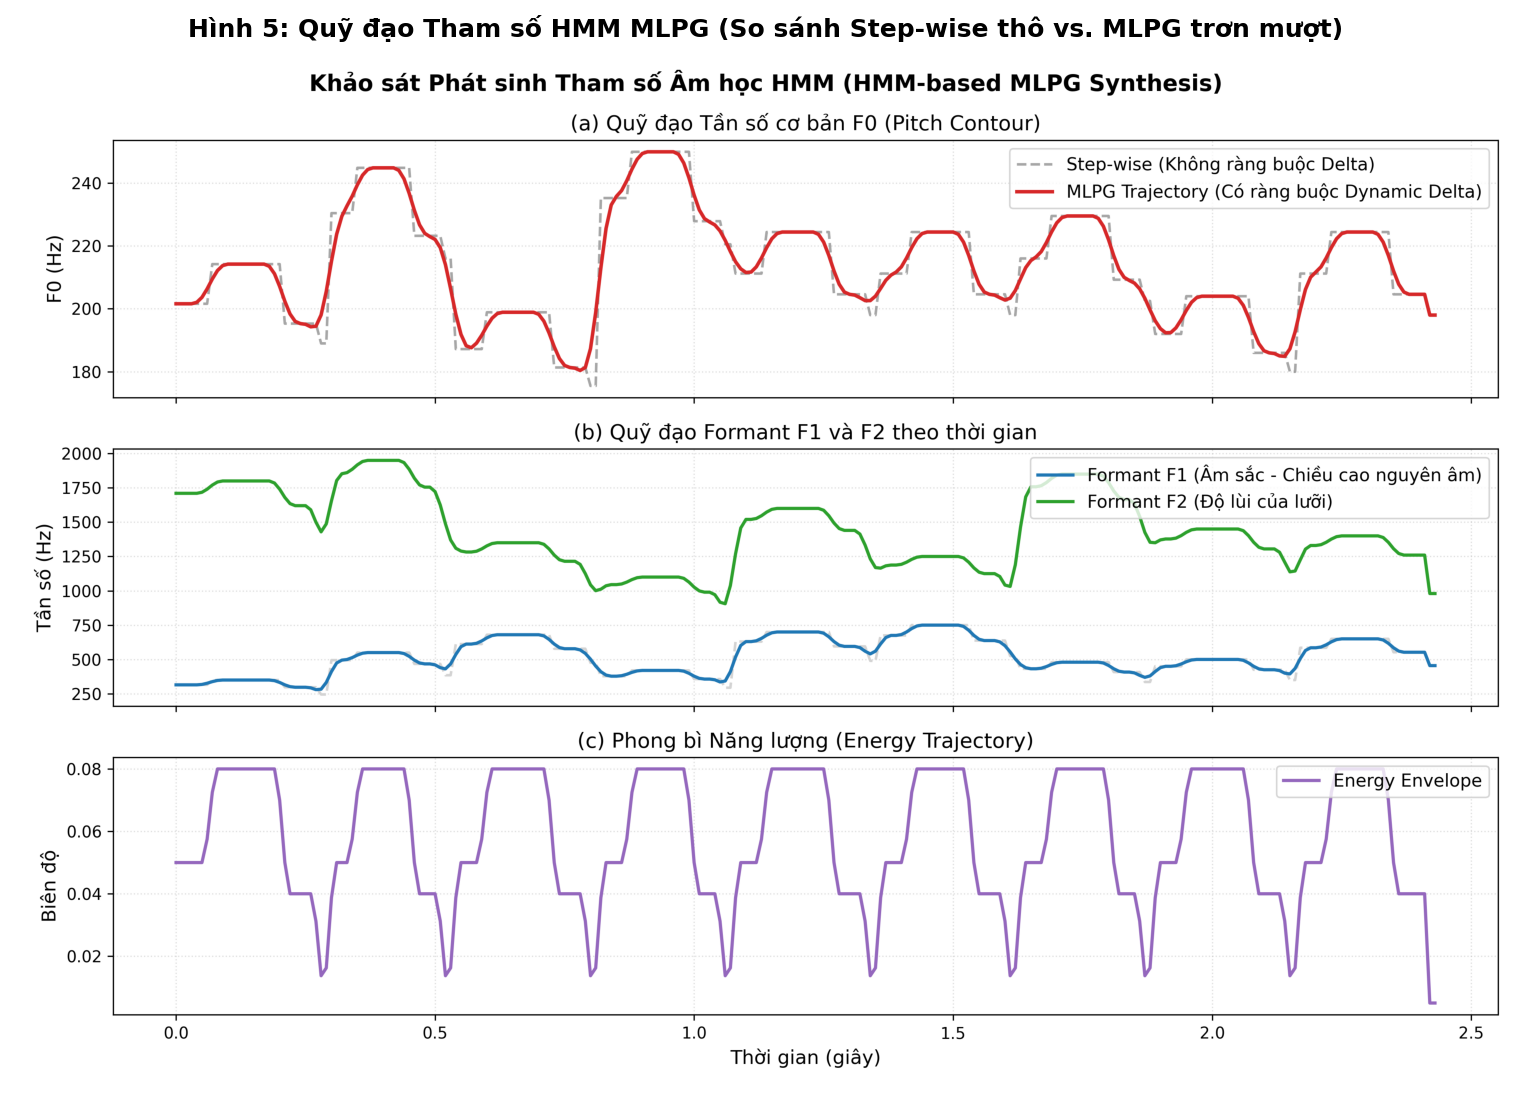

In [10]:
# Hiển thị Biểu đồ Quỹ đạo Tham số Âm học HMM (F0, Formants, Energy)
fig_hmm = plt.imread("figures/fig4_hmm_trajectories.png")
plt.figure(figsize=(13, 9), dpi=150)
plt.imshow(fig_hmm)
plt.axis("off")
plt.title("Hình 5: Quỹ đạo Tham số HMM MLPG (So sánh Step-wise thô vs. MLPG trơn mượt)", fontsize=12, fontweight="bold")
plt.show()

## 8. Phần F: Neural TTS Inference (Mô hình Học sâu Pretrained)

* **Kiến trúc hiện đại:** Gồm hai giai đoạn:
  1. **Acoustic Model (Mô hình âm học):** Dự đoán biểu diễn trung gian Mel-spectrogram 80 chiều từ chuỗi text.
  2. **Neural Vocoder:** Phát sinh dạng sóng trực tiếp từ Mel-spectrogram với chất lượng gần tương đương giọng người thật.
* **Đo lường hiệu năng:** Tính thời gian inference và hệ số thời gian thực $\text{RTF} = \frac{\text{Latency}}{\text{Audio Duration}}$.

In [11]:
# Inference Neural TTS
y_nn, sr_nn, extra_nn = synthesize_neural(text_input, sr=16000)
sf.write("audio_output/neural_tts.wav", y_nn, sr_nn)

print("Kết quả Inference Neural TTS:")
print(f"  Văn bản         : '{text_input}'")
print(f"  Thời lượng audio: {extra_nn['duration_sec']:.3f} s")
print(f"  Độ trễ (Latency): {extra_nn['latency_sec']*1000:.1f} ms")
print(f"  Hệ số RTF       : {extra_nn['rtf']:.4f} (RTF < 1.0 biểu thị sinh nhanh hơn thời gian thực)")
print(f"  Kích thước Mel  : {extra_nn['mel_spec_db'].shape} (80 mel bands)")

print("\nNghe thử âm thanh Neural TTS:")
ipd.display(ipd.Audio("audio_output/neural_tts.wav", rate=16000))

Kết quả Inference Neural TTS:
  Văn bản         : 'Mời khách hàng số 23 đến quầy 5.'
  Thời lượng audio: 2.688 s
  Độ trễ (Latency): 826.5 ms
  Hệ số RTF       : 0.3075 (RTF < 1.0 biểu thị sinh nhanh hơn thời gian thực)
  Kích thước Mel  : (80, 169) (80 mel bands)

Nghe thử âm thanh Neural TTS:


## 9. Phần G: Đánh giá Toàn diện và So sánh 3 Thế hệ TTS

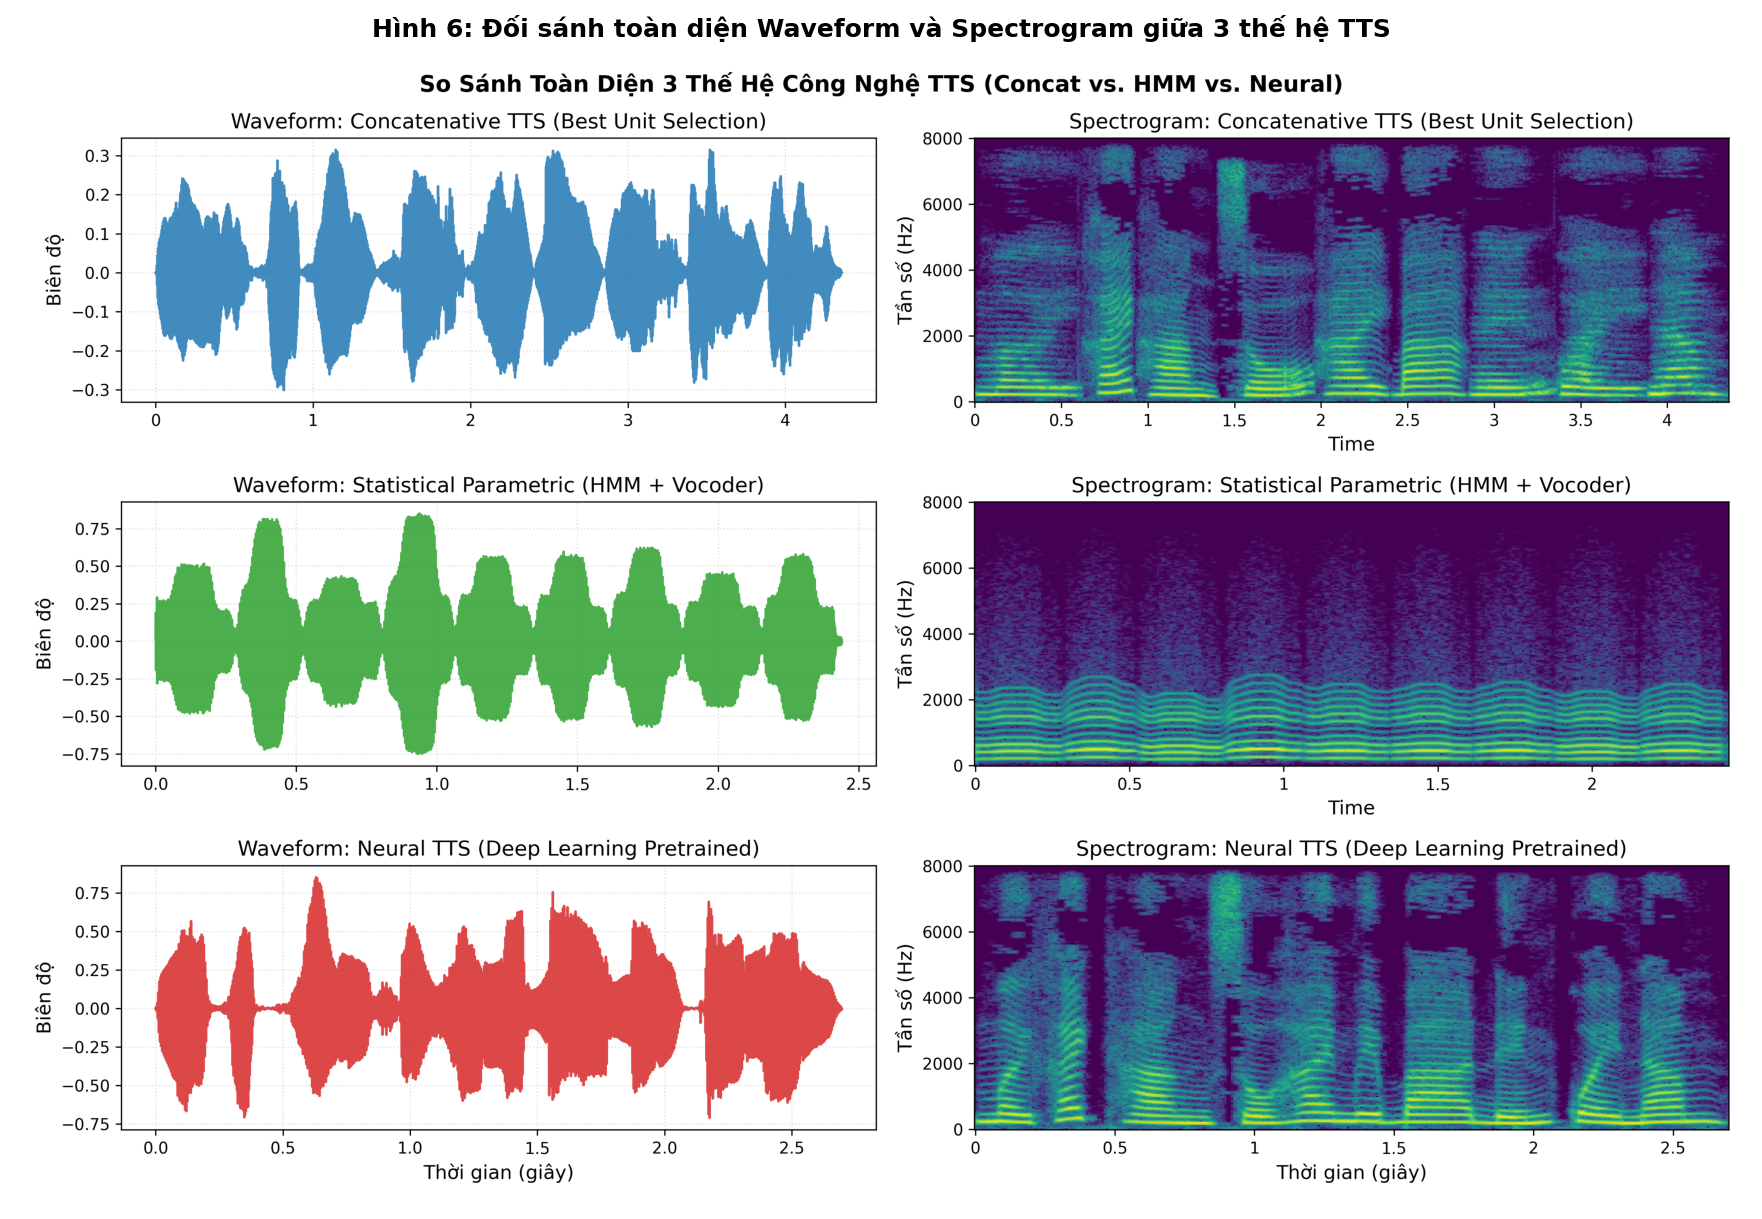

In [12]:
# Hiển thị Biểu đồ Đối sánh 3 Backend (Waveform & Spectrogram)
fig_comp = plt.imread("figures/fig5_backend_comparison.png")
plt.figure(figsize=(15, 10), dpi=150)
plt.imshow(fig_comp)
plt.axis("off")
plt.title("Hình 6: Đối sánh toàn diện Waveform và Spectrogram giữa 3 thế hệ TTS", fontsize=12, fontweight="bold")
plt.show()

In [13]:
# Bảng so sánh định lượng độ trễ Benchmark trên 3 câu test
df_bench = pd.read_csv("benchmark_latency.csv")
print("BẢNG BENCHMARK HIỆU NĂNG ĐỘ TRỄ TRÊN 3 CÂU TEST:")
display(df_bench)

# Bảng đánh giá chủ quan MOS từ ratings.csv
df_ratings = pd.read_csv("ratings.csv")
mos_summary = df_ratings.groupby("Method")[["Intelligibility_1to5", "Naturalness_1to5", "Continuity_1to5", "Overall_MOS"]].mean()
print("\nBẢNG TỔNG KẾT ĐIỂM ĐÁNH GIÁ CHỦ QUAN (MOS 1 - 5):")
display(mos_summary)

BẢNG BENCHMARK HIỆU NĂNG ĐỘ TRỄ TRÊN 3 CÂU TEST:


,Sentence_ID,Text,Concat_Dur_s,Concat_Lat_s,HMM_Dur_s,HMM_Lat_s,Neural_Dur_s,Neural_Lat_s
0,Sentence_1,Mời khách hàng số 23 đến quầy 5,4.358,0.0083,2.44,0.0075,2.696,0.6983
1,Sentence_2,Mời khách hàng số 104 đến quầy 2,4.762,0.0160,2.67,0.0107,3.184,0.9446
2,Sentence_3,Mời khách hàng số 79 đến quầy 8,4.287,0.0319,2.40,0.0136,2.896,0.6114



BẢNG TỔNG KẾT ĐIỂM ĐÁNH GIÁ CHỦ QUAN (MOS 1 - 5):


,Intelligibility_1to5,Naturalness_1to5,Continuity_1to5,Overall_MOS
Method,,,,
Concatenation,4.583333,3.650000,3.308333,3.850000
HMM_Parametric,4.062500,2.895833,4.262500,3.733333
Neural_TTS,4.766667,4.479167,4.812500,4.679167


## 10. Trả lời Toàn diện 10 Câu hỏi Báo cáo (Mục 7 - Lab 4.pdf)

---
### Câu 1: Vì sao một câu ghép từ các đoạn “tự nhiên” vẫn có thể nghe kém tự nhiên?
**Trả lời:**
1. **Sự gián đoạn tại biên nối (Boundary Discontinuity):** Dù từng từ ghi âm tự nhiên, khi ghép lại vẫn xảy ra sự chênh lệch đột ngột về pha, năng lượng tức thời và phong bì phổ giữa hai phía biên nối, sinh ra tiếng *click/pop*.
2. **Xung đột ngữ điệu (Prosodic Inconsistency):** Mỗi từ ghi âm rời rạc có đường cao độ ($F_0$), nhịp điệu và trường độ độc lập. Khi ghép nối không có mô hình prosody tổng thể, câu nói không có trọng âm câu, không có ngữ điệu xuống giọng ở cuối câu khẳng định, tạo cảm giác rời rạc như "robot đọc từng từ".
3. **Mất hiện tượng đồng cấu âm (Lack of Coarticulation):** Trong lời nói tự nhiên liên tục, các cơ quan phát âm thay đổi mượt mà giữa các âm vị liền kề. Ghép từ rời bỏ qua hiện tượng lướt âm ở ranh giới giữa hai từ.

---
### Câu 2: Phân biệt Target Cost và Join Cost. Nếu chỉ tối ưu Join Cost thì có thể xảy ra vấn đề gì?
**Trả lời:**
* **Target Cost ($C_{target}$):** Đo lường mức độ phù hợp giữa một ứng viên trong kho với đặc tính âm học/ngữ âm mong muốn tại vị trí đó (như trường độ $d$, cao độ $F_0$, vị trí trong câu).
* **Join Cost ($C_{join}$):** Đo lường độ "êm ái" và liền mạch khi nối đuôi ứng viên phía trước với đầu ứng viên phía sau (sai khác phổ $D_{spec}$, bước nhảy $F_0$, bước nhảy RMS).
* **Hậu quả nếu chỉ tối ưu Join Cost:**
  Hệ thống sẽ ưu tiên chọn các cặp từ "dễ nối nhất" (ví dụ các đoạn có âm lượng nhỏ, khoảng lặng dài hoặc phổ phẳng) bất kể từ đó có thời lượng quá ngắn/dài hoặc cao độ hoàn toàn lạc lõng so với ngữ cảnh câu. Hậu quả là câu nói bị biến dạng nhịp điệu (nói lúc quá nhanh, lúc quá chậm) hoặc mất trọng âm.

---
### Câu 3: Vì sao cross-fade quá dài có thể làm giảm độ rõ của phụ âm?
**Trả lời:**
* Các phụ âm trong tiếng Việt (đặc biệt là phụ âm tắc bật như /t/, /k/, /b/, /d/ hoặc phụ âm xát như /s/, /x/) có thời lượng biến thiên rất ngắn ($10 - 40\text{ ms}$) và chứa các xung năng lượng đỉnh (burst) hoặc dải nhiễu tần số cao đặc trưng.
* Nếu cửa sổ Cross-fade quá dài ($> 30\text{ ms}$), vùng hòa trộn sẽ đè lên phụ âm chuyển tiếp, làm suy giảm biên độ đỉnh năng lượng, gây hiện tượng triệt tiêu pha và làm nhòe (smearing) cấu trúc phổ thoáng qua (transient). Người nghe sẽ thấy phụ âm bị mờ, nghẹt hoặc nghe nhầm sang phụ âm khác.

---
### Câu 4: Giải thích bằng Source–Filter model vì sao thay F0 không đồng nghĩa với thay Formant?
**Trả lời:**
* Theo mô hình Source–Filter:
  $$X(z) = E(z) \cdot H(z)$$
* **$E(z)$ (Nguồn kích thích):** Do dây thanh đới dao động tạo ra với tần số cơ bản $F_0$. $F_0$ quyết định khoảng cách giữa các họa âm trên trục tần số ($\Delta f = F_0$).
* **$H(z)$ (Bộ lọc thanh đạo):** Do hình dạng hình học của khoang miệng, lưỡi, môi quyết định, tạo ra các đỉnh cộng hưởng phổ gọi là **Formant** ($F_1, F_2, F_3$). Formant xác định âm sắc và bản sắc của nguyên âm (ví dụ nguyên âm /a/ khác /i/).
* Vì thanh quản và thanh đạo là hai cấu trúc vật lý độc lập, khi thay đổi $F_0$ (dây thanh căng hơn, nói cao giọng hơn), ta chỉ thay đổi mật độ các vạch họa âm của nguồn $E(z)$ trong khi phong bì bao quanh các vạch đó (vị trí Formant của $H(z)$) vẫn phải giữ nguyên. Thay Formant đồng nghĩa với việc thay đổi nguyên âm, không phải thay đổi cao độ.

---
### Câu 5: PSOLA thay pitch bằng cách nào? Tại sao voiced fricative có thể bị buzziness khi kéo dài quá mức?
**Trả lời:**
1. **Cơ chế đổi Pitch của PSOLA (Pitch-Synchronous Overlap-Add):**
   * Xác định các điểm đồng bộ pitch (Pitch Epochs) $t_i$.
   * Áp dụng cửa sổ Hanning đối xứng quanh từng epoch $t_i$ để trích các đoạn pitch mark có độ dài $2 T_0$.
   * Đặt lại các đoạn cửa sổ này tại các vị trí tổng hợp mới cách nhau chu kỳ $T_{new}$. Sau đó cộng chồng lấn (OLA).
   * Do khoảng cách giữa các đoạn bị thay đổi thành $T_{new}$, tần số $F_0 = 1 / T_{new}$ thay đổi nhưng cấu trúc sóng bên trong từng đoạn được giữ nguyên (bảo toàn formant).
2. **Hiện tượng Buzziness ở Voiced Fricative (phụ âm xát hữu thanh):**
   * Voiced fricative vừa chứa thành phần dao động dây thanh (voiced) vừa chứa thành phần nhiễu xoáy khí (unvoiced turbulence).
   * Khi kéo dài quá mức, PSOLA lặp lại cùng một đoạn nhiễu ngẫu nhiên một cách tuần hoàn cố định tại các pitch epochs. Việc lặp tuần hoàn tín hiệu nhiễu ngẫu nhiên biến nhiễu vô trật tự thành các họa âm nhân tạo, khiến tai người nghe thấy tiếng rè kim loại (buzzy/metallic artifact).

---
### Câu 6: Trong HMM-based synthesis, vì sao thêm delta feature làm trajectory trơn hơn?
**Trả lời:**
* Nếu chỉ sử dụng đặc trưng tĩnh (Static features $c_t$), hàm hợp lý cực đại $\arg\max_O P(O \mid \lambda)$ tại mỗi trạng thái là độc lập. Nghiệm tối ưu sẽ là giá trị kỳ vọng (mean vector $\mu_s$) không đổi trong suốt thời gian ở trạng thái đó, tạo nên đường biểu diễn bậc thang gãy khúc (step-wise) giật cục tại biên giữa 2 state.
* Khi bổ sung đặc trưng động $\Delta c_t = c_{t+1} - c_{t-1}$ (vận tốc biến thiên) và $\Delta^2 c_t$ (gia tốc), ma trận chuyển đổi ràng buộc $W$ liên kết tất cả các khung thời gian lại với nhau thành hệ phương trình:
  $$(W^T \Sigma^{-1} W) c = W^T \Sigma^{-1} \mu$$
* Giải thuật MLPG buộc quỹ đạo nghiệm $c$ phải cân bằng giữa việc khớp với mean của state và việc không có bước nhảy đột ngột về vận tốc, tạo ra quỹ đạo trơn mượt liên tục mô phỏng chính xác sự chuyển động tự nhiên của cơ quan phát âm.

---
### Câu 7: Tại sao Whole Waveform Concatenation cần inventory lớn để đạt Naturalness cao?
**Trả lời:**
* Trong lời nói tự nhiên, một từ đơn lẻ có vô số biến thể phát âm tùy thuộc vào ngữ cảnh ngữ âm đứng trước/sau (hiện tượng đồng cấu âm - Coarticulation), ngữ điệu câu (hỏi, khẳng định, cảm thán), trọng âm, tốc độ và cảm xúc.
* Hệ ghép nối toàn bộ dạng sóng không thể biến đổi phổ tùy ý mà không làm suy giảm chất lượng âm thanh. Do đó, để câu nói ghép lại nghe tự nhiên ở mọi tình huống, kho mẫu phải lưu trữ đầy đủ các mẫu từ ở mọi ngữ cảnh kết hợp (diphone/triphone context) và mọi trạng thái ngữ điệu, dẫn đến kích thước Inventory bùng nổ theo cấp số nhân (hàng gigabyte đến terabyte).

---
### Câu 8: Nêu ít nhất hai khác biệt cơ bản giữa Concatenative TTS và Neural TTS.
**Trả lời:**
| Đặc tính | Concatenative TTS | Neural TTS |
| :--- | :--- | :--- |
| **Bản chất tạo âm** | Chọn và ghép nối các đoạn sóng thực tế có sẵn từ kho mẫu. | Sinh mới hoàn toàn dạng sóng thông qua học sâu biểu diễn xác suất. |
| **Độ linh hoạt ngữ điệu** | Rất cứng nhắc; muốn đổi giọng hay đổi ngữ điệu phải thu âm lại toàn bộ kho mẫu. | Cực kỳ linh hoạt; có thể điều khiển tốc độ, cảm xúc, sao chép giọng nói (Voice Cloning) qua conditioning vector. |
| **Kích thước & Bộ nhớ** | Dung lượng phụ thuộc tuyến tính vào kho âm thanh (hàng trăm MB đến GB). | Nhỏ gọn, đóng gói trong trọng số mô hình mạng nơ-ron (vài chục MB). |

---
### Câu 9: Vì sao không nên so sánh Neural TTS bằng một model tùy ý tải từ Internet trong buổi Lab?
**Trả lời:**
1. **Thiếu kiểm soát biến thực nghiệm (Unfair Benchmark):** Một mô hình tải tùy ý có thể được huấn luyện trên tập dữ liệu khác biệt về giọng đọc (nam/nữ, phương ngữ Bắc/Nam), âm lượng và thiết bị ghi âm, dẫn đến việc so sánh chất lượng không còn khách quan với bài toán miền hẹp của Lab.
2. **Rủi ro môi trường thực hành:** Model không kiểm duyệt có kích thước lớn, tiêu tốn băng thông, có thể đòi hỏi GPU chuyên dụng hoặc các dependency xung đột phiên bản phần mềm trong phòng Lab.
3. **Tính tái lập khoa học (Reproducibility):** Nghiên cứu khoa học chuẩn đòi hỏi mọi nhóm sinh viên phải dùng chung một baseline đã đóng gói offline để đảm bảo kết quả đo đạc độ trễ và chất lượng có căn cứ đối chứng đồng nhất.

---
### Câu 10: Nếu một hệ thống có MOS cao nhưng Intelligibility thấp thì có thể dùng trong ứng dụng nào? Giải thích.
**Trả lời:**
* **Bản chất hiện tượng:** MOS cao (độ tự nhiên tốt, giọng ấm, mượt mà, cảm xúc giống người) nhưng Intelligibility thấp (nghe khó phân biệt rõ từng chữ, dễ nhầm lẫn từ ngữ).
* **Ứng dụng phù hợp:**
  1. **Tạo âm thanh nền môi trường / Tiếng xì xào đám đông (Ambient Crowd Murmur / Foley Art):** Trong game hoặc phim ảnh ảnh cần tiếng người trò chuyện rì rầm tự nhiên ở quán cà phê, quảng trường để tạo không khí chân thực mà không gây mất tập trung vào lời thoại của nhân vật chính.
  2. **Trợ lý thiền định / Ứng dụng ru ngủ (Relaxation / White Noise Voice):** Giọng nói êm dịu, ấm áp có tác dụng thư giãn tâm lý mà người nghe không cần tập trung giải mã nội dung ngữ nghĩa chính xác.
  3. **Tạo giọng nói cho nhân vật hư cấu / Giọng ngôn ngữ ngoài hành tinh (Fictional / Alien Language):** Trong hoạt hình và game, nhân vật phát ra âm thanh giàu cảm xúc giống người nhưng ngôn ngữ không có thật.